# Customer churn and spending · measured study review

**PySpark / MLlib · MLflow · stratified CV · external transfer · Databricks integration**

This notebook presents measured results from the supplied customer CSVs. The rewritten pipelines were executed locally. Databricks notebooks and the optional AutoML comparison are provided separately; no new cloud execution is claimed.

The target is the supplied churn label or recorded total spending. Observation timestamps, a future churn horizon and spending currency are not established.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").exists()
)
RESULTS = PROJECT_ROOT / "reports/provided-v1"
manifest = json.loads((RESULTS / "manifest.json").read_text())
quality = json.loads((RESULTS / "quality.json").read_text())
audit = json.loads((RESULTS / "shift_audit.json").read_text())
classification = json.loads((RESULTS / "classification.json").read_text())
regression = json.loads((RESULTS / "regression.json").read_text())
print("Run:", manifest["run_id"])
print(
    "Runtime:",
    manifest["environment"]["python"],
    "Python /",
    manifest["environment"]["spark"],
    "Spark /",
    manifest["environment"]["mlflow"],
    "MLflow",
)

Run: provided-v1
Runtime: 3.11.17 Python / 3.5.7 Spark / 3.5.0 MLflow


## 1. Reconcile every input record

Bronze preserves strings, silver contains typed valid rows, and quarantine records why a source row was unusable. Missing predictors are retained for train-only imputation. The observed source quality issue is one completely empty development row.

In [2]:
display(
    pd.DataFrame([{"source": source, **counts} for source, counts in quality["sources"].items()])
)
assert quality["reconciled"]
display(pd.DataFrame(quality["split_counts"]))

,source,input_rows,valid_rows,invalid_rows
0,development,440833,440832,1
1,external,64374,64374,0


,source,split,churn,count
0,development,test,0.0,28625
1,development,test,1.0,37500
2,development,train,0.0,133583
3,development,train,1.0,174999
4,development,validate,0.0,28625
5,development,validate,1.0,37500
6,external,external,0.0,33881
7,external,external,1.0,30493


## 2. Audit source differences before interpreting scores

Customer IDs are source-local bookkeeping, never model features. Shared ID values have different records. Conditional churn relationships also change between files. These observations do not establish temporal drift or a specific causal/leakage mechanism.

,source,rows,churn_rate
0,development,118513,1.000000
1,external,33138,0.609904


,shared_id_values,identical_rows_for_shared_id
0,62995,0


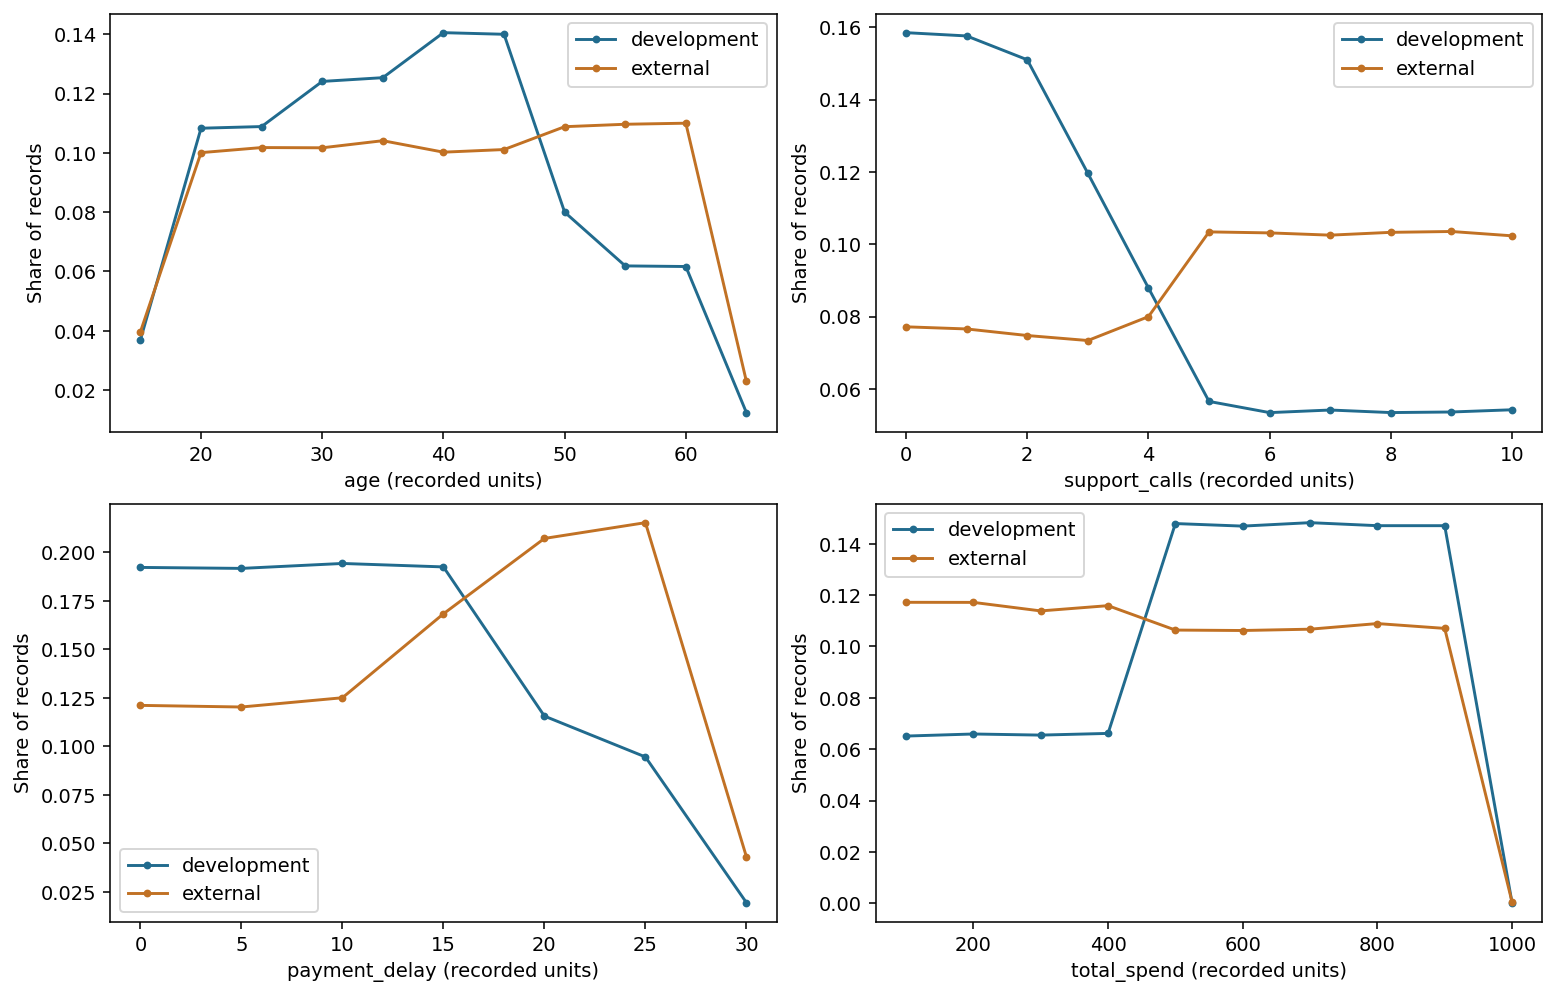

In [3]:
display(pd.DataFrame(audit["support_calls_ge6"]))
display(pd.DataFrame([audit["identity_overlap"]]))
display(Image(filename=str(RESULTS / "report/source_distributions.png")))

## 3. Freeze the information set and selection protocol

The development file is stratified 70/15/15. Only a declared sample of development training enters CV. Each fold learns its own preprocessing. The selected candidate is refitted on all training rows; validation selects the F1 decision threshold. Internal test and the external file do not tune the candidate.

The CV search sampled 77,490 rows; final fitting used 308,582 training rows. Missing predictors, category frequencies and encodings are learned from the appropriate training subset only.

In [4]:
from churn_study.config import feature_columns

print("Classification features:", feature_columns("classification"))
print("Regression features:", feature_columns("regression"))
assert "customer_id" not in feature_columns("classification")
assert "churn" not in feature_columns("regression")
display(pd.DataFrame(classification["candidates"])[["name", "mean", "std"]])
display(pd.DataFrame(regression["candidates"])[["name", "mean", "std"]])

Classification features: ('age', 'tenure', 'usage_frequency', 'support_calls', 'payment_delay', 'last_interaction', 'total_spend', 'gender', 'subscription_type', 'contract_length')
Regression features: ('age', 'tenure', 'usage_frequency', 'support_calls', 'payment_delay', 'last_interaction', 'gender', 'subscription_type', 'contract_length')


,name,mean,std
0,gbt_depth5,0.997399,0.000202
1,gbt_depth3,0.988957,0.000275
2,logistic_l2_0.001,0.959986,0.001374
3,logistic_l2_0.1,0.958749,0.001412
4,logistic_l2_1,0.955967,0.001636


,name,mean,std
0,gbt_depth3,225.827584,1.002241
1,ridge_0.1,231.444891,0.758476
2,ols,231.444909,0.758673
3,ridge_0.001,231.444910,0.758671
4,lasso_0.001,231.444911,0.758645
5,elastic_net_0.1,231.444943,0.757742
6,lasso_0.1,231.445084,0.757043
7,ridge_10,231.450121,0.740065
8,lasso_10,232.472421,0.686967


## 4. Compare matched held-out classification results

The external result is deliberately retained. A high internal score does not establish that the model transfers to the other file. Brier score and calibration reveal probability errors that ROC-AUC alone does not capture.

,partition,estimator,roc_auc,average_precision,f1,brier,lift_at_top_10pct
0,validate,model,0.997373,0.998425,0.994679,0.012881,1.763333
1,validate,baseline,0.500000,0.567108,0.723764,0.245497,0.999124
2,test,model,0.997207,0.998338,0.994492,0.013199,1.763333
3,test,baseline,0.500000,0.567108,0.723764,0.245497,0.999391
4,external,model,0.616157,0.516035,0.657934,0.435983,0.890941
5,external,baseline,0.500000,0.473685,0.642858,0.258035,0.996529


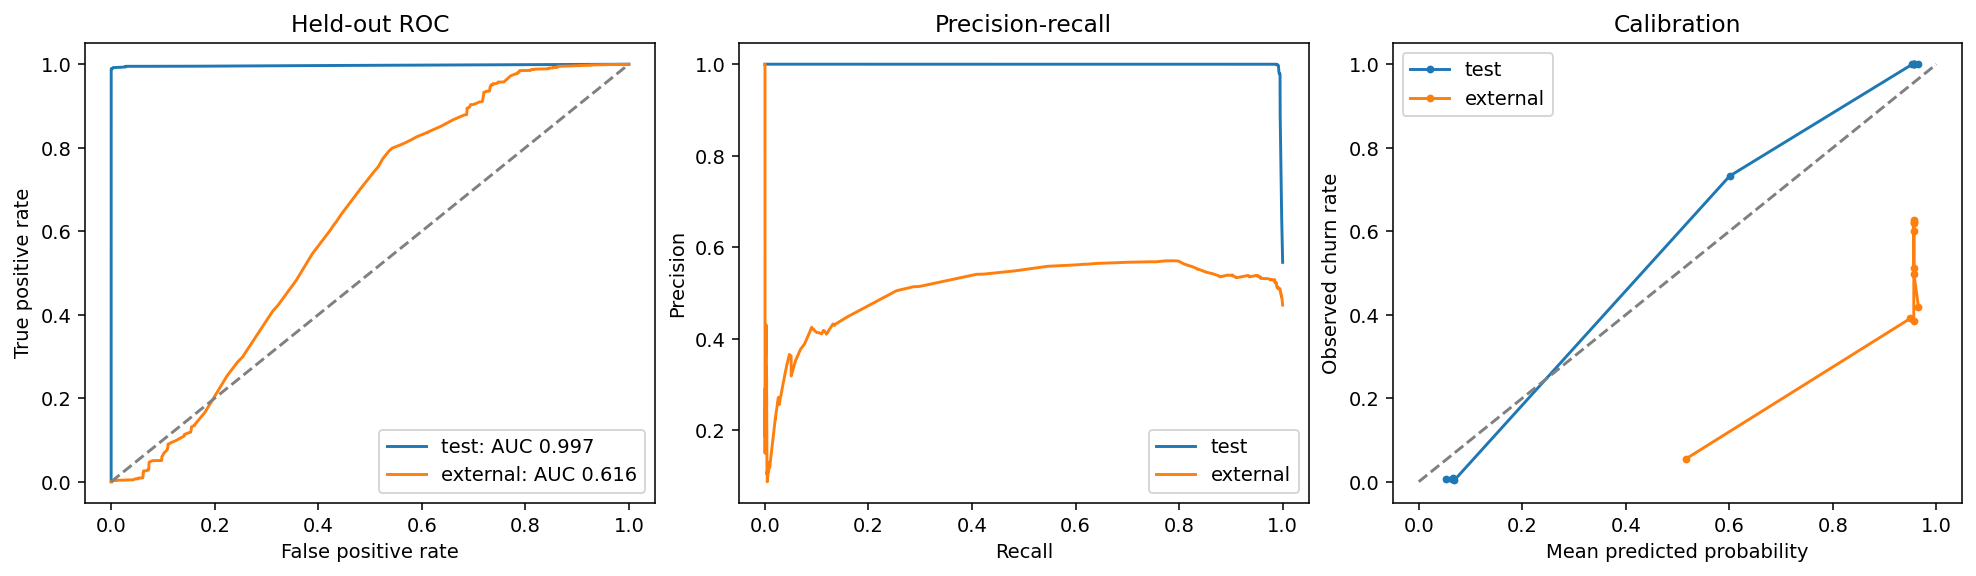

In [5]:
rows = []
for partition, evaluation in classification["evaluations"].items():
    for estimator in ["model", "baseline"]:
        metrics = evaluation[estimator]
        rows.append(
            {
                "partition": partition,
                "estimator": estimator,
                **{
                    name: metrics[name]
                    for name in ["roc_auc", "average_precision", "f1", "brier", "lift_at_top_10pct"]
                },
            }
        )
display(pd.DataFrame(rows))
display(Image(filename=str(RESULTS / "report/classification_diagnostics.png")))

## 5. Spending estimation and regularization

OLS, Ridge, Lasso, Elastic Net and GBT are compared by CV. Regularization is not assumed to improve every dataset. Coefficient-path refits use training data only and do not change model selection.

Negative external R² compares with the external file's own mean. The deployable baseline uses the training mean; the report shows both references explicitly.

,partition,estimator,rows,mae,rmse,r2
0,validate,model,66125,187.260059,225.874847,1.198391e-01
1,validate,baseline,66125,199.863485,240.761598,-1.787792e-06
2,test,model,66125,186.713236,225.220548,1.207826e-01
3,test,baseline,66125,199.228366,240.192798,-4.693269e-07
4,external,model,64374,229.336150,265.836256,-3.841483e-02
5,external,baseline,64374,236.632568,276.147417,-1.205324e-01


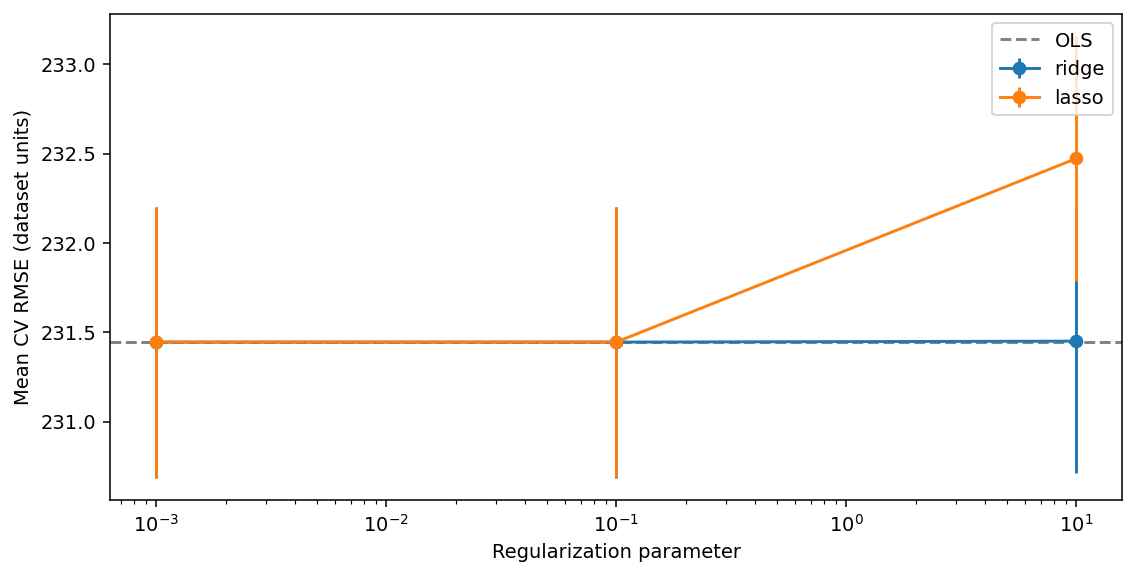

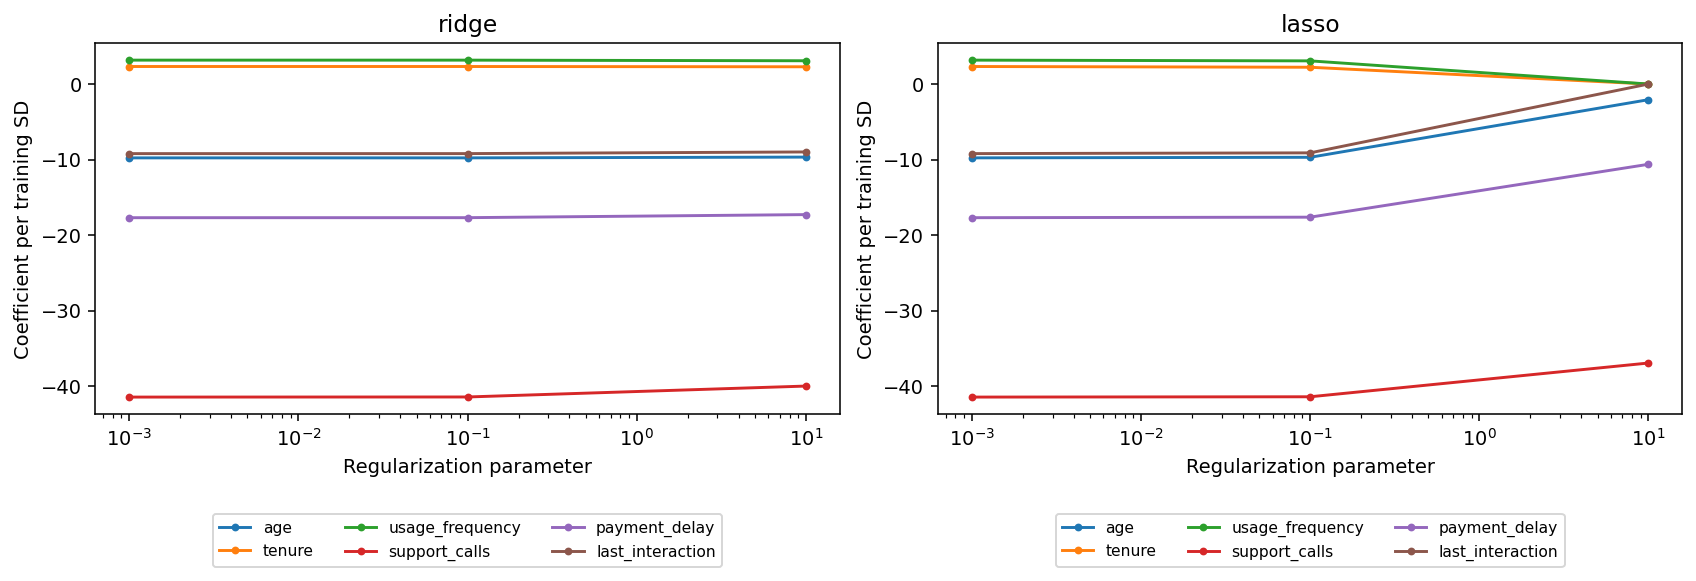

In [6]:
display(
    pd.DataFrame(
        [
            {"partition": partition, "estimator": estimator, **evaluation[estimator]}
            for partition, evaluation in regression["evaluations"].items()
            for estimator in ["model", "baseline"]
        ]
    )
)
display(Image(filename=str(RESULTS / "report/regularization_cv.png")))
display(Image(filename=str(RESULTS / "report/coefficient_paths.png")))

## 6. Uncertainty, model lineage and reproducibility

Bootstrap intervals condition on the fitted model and the evaluated rows. They exclude retraining/split uncertainty. MLflow contains candidate CV runs, dataset fingerprints, parameters, raw-input signatures and complete preprocessing/model pipelines. Native load-back predictions were checked for equality. The registry alias is `candidate`, not automatic production approval.

In [7]:
display(
    pd.DataFrame(
        [
            {"task": task, **result["lineage"]}
            for task, result in [("classification", classification), ("regression", regression)]
        ]
    )
)
display(
    pd.DataFrame(
        [
            {"partition": partition, "metric": metric, **interval}
            for partition, evaluation in classification["evaluations"].items()
            for metric, interval in evaluation["bootstrap"]["intervals"].items()
        ]
    )
)
assert classification["lineage"]["roundtrip_predictions_equal"]
assert regression["lineage"]["roundtrip_predictions_equal"]

,task,run_id,model_uri,registered_model,version,alias,native_path,roundtrip_predictions_equal,signature_input_columns,promotion_policy
0,classification,3979bc4a5a4f4a22940e9c607eaa3fef,runs:/3979bc4a5a4f4a22940e9c607eaa3fef/model,customer_study_classification,1,candidate,models/classification,True,"[age, tenure, usage_frequency, support_calls, ...",Candidate is not automatically approved for re...
1,regression,ea7217458e3440a8ac709ae91c971cad,runs:/ea7217458e3440a8ac709ae91c971cad/model,customer_study_regression,1,candidate,models/regression,True,"[age, tenure, usage_frequency, support_calls, ...",Candidate is not automatically approved for re...


,partition,metric,low,high
0,test,roc_auc,0.996808,0.997643
1,test,average_precision,0.998101,0.998589
2,external,roc_auc,0.612145,0.620479
3,external,average_precision,0.512952,0.519440


## Conclusion and reproduction

The selected classifier has internal ROC-AUC around **0.997** and external ROC-AUC around **0.616**. Its external top-decile lift is below one. The specification does not demonstrate useful transfer for customer prioritization in the second file. Further work needs a trustworthy independent dataset or timestamped sampling process, rather than repeated tuning against these external labels.

- Reproduce the full study with the `churn run` command in README.
- Inspect the self-contained report in `reports/provided-v1/report/index.html`.
- Score raw records with `churn score`; the handoff ZIP includes portable native model examples.
- Run the platform notebooks in `databricks/` in an authorized compatible workspace.
- The optional AutoML notebook applies the same feature whitelist and holdout partitions and records actual trial metric keys. No AutoML result from the rewritten version is currently claimed.